In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [27]:
wine = load_wine()
wine_df = pd.DataFrame(wine.data, columns=wine.feature_names)
wine_df['target']= pd.DataFrame(wine.target, columns=['target'])

In [35]:
print("Shape of dataset;",wine_df.shape)
display("Top 7 rows of dataset:", wine_df.head(7))
display("Stats summary of dataframe:", wine_df.describe())
#print("Info of dataframe:", wine_df.info())
print("Any null values in dataframe:", wine_df.isnull().sum())

Shape of dataset; (178, 14)


'Top 7 rows of dataset:'

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0
5,14.20,1.76,2.45,15.2,112.0,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450.0,0
6,14.39,1.87,2.45,14.6,96.0,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290.0,0


'Stats summary of dataframe:'

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


Any null values in dataframe: alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64


In [29]:
wine_df['target'].value_counts()

target
1    71
0    59
2    48
Name: count, dtype: int64

In [42]:
print("duplicated rows of dataset:",wine_df[wine_df.duplicated()])
print("cleaned wine datset (wine_df)")
wine_df=wine_df[~wine_df.duplicated()]
wine_df.head()

duplicated rows of dataset: Empty DataFrame
Columns: [alcohol, malic_acid, ash, alcalinity_of_ash, magnesium, total_phenols, flavanoids, nonflavanoid_phenols, proanthocyanins, color_intensity, hue, od280/od315_of_diluted_wines, proline, target]
Index: []
cleaned wine datset (wine_df)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


array([ 14.13,   4.1 ,   2.74,  24.5 ,  96.  ,   2.05,   0.76,   0.56,
         1.35,   9.2 ,   0.61,   1.6 , 560.  ])

In [45]:
wine_df.columns

Index(['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium',
       'total_phenols', 'flavanoids', 'nonflavanoid_phenols',
       'proanthocyanins', 'color_intensity', 'hue',
       'od280/od315_of_diluted_wines', 'proline', 'target'],
      dtype='str')

In [ ]:
features=['alcohol', 'malic_acid', 'magnesium','total_phenols', 'flavanoids', 
       'proanthocyanins', 'color_intensity', 'hue','od280/od315_of_diluted_wines', 'proline']

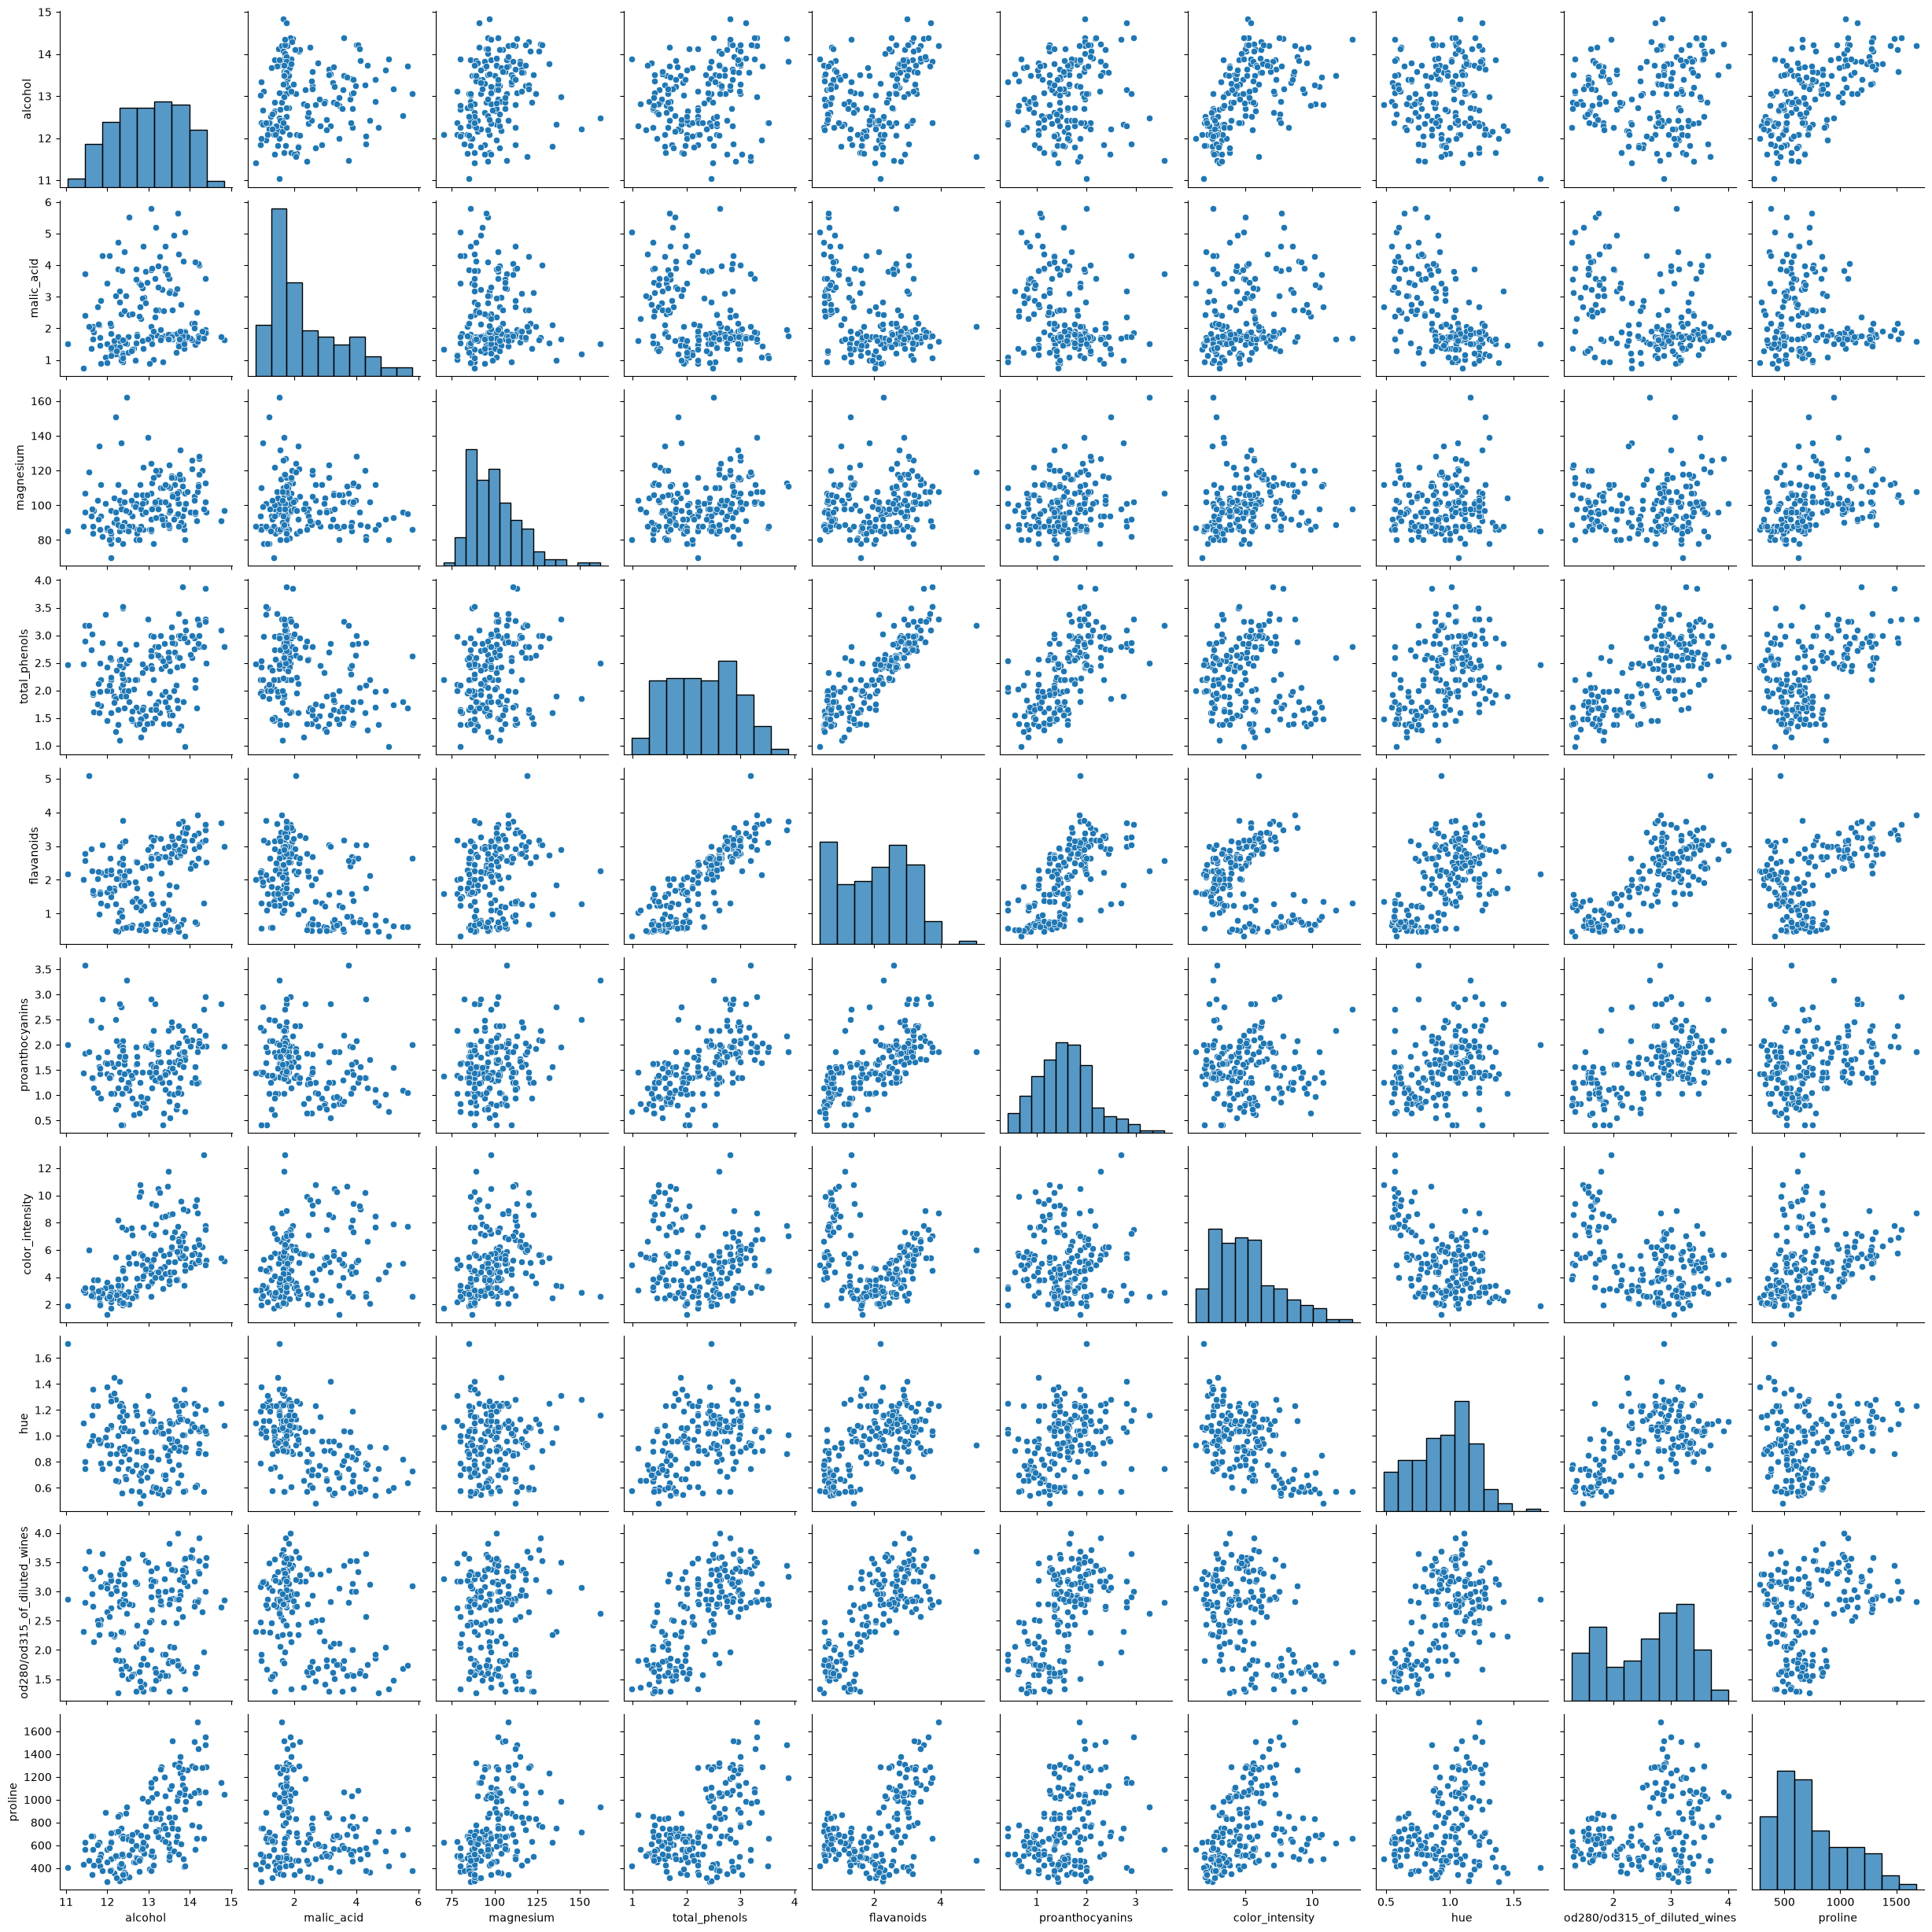

In [53]:
g=sns.pairplot(wine_df,vars=features)
plt.show()

g.savefig("wine_features_pairplot.png", dpi=300, bbox_inches="tight")


In [2]:
import pandas as pd

In [4]:
df= pd.read_csv("C:\\Users\\bharg\\Shriji\\UZH CHE 101 and CHE 103\\UZH CHE 103 ADVANCED DATA SCIENCE\\ChemicalDataScience103\\lectures\\session08\\materials\\PubChem_compound_text_salicylic acid.csv")

In [5]:
df.columns

Index(['Compound_CID', 'Name', 'Synonyms', 'Molecular_Weight',
       'Molecular_Formula', 'Polar_Area', 'Complexity', 'XLogP',
       'Heavy_Atom_Count', 'H-Bond_Donor_Count', 'H-Bond_Acceptor_Count',
       'Rotatable_Bond_Count', 'InChI', 'SMILES', 'InChIKey', 'IUPAC_Name',
       'Exact_Mass', 'Monoisotopic_Mass', 'Charge', 'Covalent_Unit_Count',
       'Isotopic_Atom_Count', 'Total_Atom_Stereo_Count',
       'Defined_Atom_Stereo_Count', 'Undefined_Atom_Stereo_Count',
       'Total_Bond_Stereo_Count', 'Defined_Bond_Stereo_Count',
       'Undefined_Bond_Stereo_Count', 'Linked_PubChem_Literature_Count',
       'Linked_PubChem_Patent_Count', 'Linked_PubChem_Patent_Family_Count',
       'MeSH_Headings', 'Annotation_Content', 'Annotation_Type_Count',
       'Linked_BioAssays', 'Create_Date', 'Data_Source',
       'Data_Source_Category', 'Tagged_by_PubChem'],
      dtype='str')

In [6]:
df.head(10)

,Compound_CID,Name,Synonyms,Molecular_Weight,Molecular_Formula,Polar_Area,Complexity,XLogP,Heavy_Atom_Count,H-Bond_Donor_Count,...,Linked_PubChem_Patent_Count,Linked_PubChem_Patent_Family_Count,MeSH_Headings,Annotation_Content,Annotation_Type_Count,Linked_BioAssays,Create_Date,Data_Source,Data_Source_Category,Tagged_by_PubChem
0,338,Salicylic Acid,salicylic acid|2-Hydroxybenzoic acid|69-72-7|o...,138.12,C7H6O3,57.5,133.0,2.3,10,2,...,103564,51503,Keralyt|compound W|Salicylic Acid,Biological Test Results|Interactions and Pathw...,19,155|157|161|165|167|175|179|248|485|568|583|59...,20040916,001Chemical|10X CHEM|1st Scientific|3WAY PHARM...,Chemical Vendors|Curation Efforts|Governmental...,C254 - Anti-Infective Agent > C52588 - Antibac...
1,13637,"Salicylic acid, hydrazide",2-Hydroxybenzohydrazide|936-02-7|Salicyl hydra...,152.15,C7H8N2O2,75.4,149.0,0.6,11,3,...,3190,1483,salicyl hydrazide|2-hydroxybenzohydrazide,Biological Test Results|Interactions and Pathw...,11,155|157|161|165|167|175|192|248|256|330|93518|...,20050326,001Chemical|10X CHEM|3WAY PHARM INC|A&J Pharmt...,Chemical Vendors|Curation Efforts|Governmental...,NaN
2,3085170,Salicylic acid monoethanolamine,Salicylic acid monoethanolamine|MEA-SALICYLATE...,199.20,C9H13NO4,104.0,143.0,NaN,14,4,...,374,147,NaN,Chemical and Physical Properties|Classificatio...,7,NaN,20050809,ABI Chem|Alfa Chemistry|BenchChem|BOC Sciences...,Chemical Vendors|Curation Efforts|Governmental...,NaN
3,90407,Salicylic acid ethanolamide,24207-38-3|N-(2-Hydroxyethyl)salicylamide|Sali...,181.19,C9H11NO3,69.6,172.0,0.7,13,3,...,100,36,NaN,Biological Test Results|Classification|Literat...,8,598|602|619|629|630|631|633|639|640|648|687|69...,20050326,"10X CHEM|A&J Pharmtech CO., LTD.|A2B Chem|AA B...",Chemical Vendors|Curation Efforts|Governmental...,NaN
4,89978,4-(Dimethylamino)salicylic acid,4-(Dimethylamino)-2-hydroxybenzoic acid|23050-...,181.19,C9H11NO3,60.8,193.0,2.1,13,2,...,144,26,NaN,Classification|Literature|Patents|Safety and H...,6,NaN,20050327,001Chemical|10X CHEM|1st Scientific|3WAY PHARM...,Chemical Vendors|Curation Efforts|Governmental...,NaN
5,96096,N'-(1-Methylethyl)salicylic acid hydrazide,"Salicylic acid, 2-isopropylhydrazide|K4DF8QNH1...",194.23,C10H14N2O2,61.4,195.0,1.9,14,3,...,0,0,NaN,Biological Test Results|Classification|Literat...,5,1145383|1145384,20050326,AAA Chemistry|ABI Chem|Ambinter|ChEMBL|ChemDB|...,Chemical Vendors|Curation Efforts|Governmental...,NaN
6,139539,"Salicylic acid, 4-nitro-, methyl ester","13684-28-1|Salicylic acid, 4-nitro-, methyl es...",197.14,C8H7NO5,92.4,236.0,2.7,14,1,...,274,46,NaN,Biological Test Results|Classification|Literat...,5,248|256,20050326,001Chemical|10X CHEM|1st Scientific|A2B Chem|A...,Chemical Vendors|Curation Efforts|Governmental...,NaN
7,390924,Salicylic acid propargylester,NSC689145|Salicylic acid propargylester|prop-2...,176.17,C10H8O3,46.5,226.0,2.5,13,1,...,0,0,NaN,Biological Test Results|Chemical and Physical ...,5,1|3|5|7|9|13|15|21|23|25|31|33|35|37|41|43|45|...,20050326,"ABI Chem|AHH Chemical co.,ltd|Ambinter|Aurora ...",Chemical Vendors|Curation Efforts|Governmental...,NaN
8,586463,4-(2-Hydroxyethoxy)salicylic Acid,4-(2-Hydroxyethoxy)salicylic acid|163451-82-9|...,198.17,C9H10O5,87.0,194.0,1.3,14,3,...,52,21,NaN,Classification|Patents|Safety and Hazards|Spec...,4,NaN,20050327,10X CHEM|A2B Chem|AA BLOCKS|AbaChemScene|abcr ...,Chemical Vendors|Curation Efforts|Governmental...,NaN
9,71309006,Salicylic acid-d6,"Salicylic acid-d6|285979-87-5|deuterio 2,3,4,5...",144.16,C7H6O3,57.5,133.0,2.3,10,2,...,3,2,NaN,Literature|Patents,2,NaN,20130517,10X CHEM|A2B Chem|AA BLOCKS|AbaChemScene|Amadi...,Chemical Vendors|Governmental Organizations|Jo...,NaN


In [ ]:
# find XlogP

In [ ]:
# one sample ttest
#t_value,p_value=stats.ttest_1samp(samples, mean)
#critical_value = 0.05 (lower then alternate hypothesis accepted)

In [ ]:
#two sample ttest
#assumption: two pop has equal size, variances of two pop are equal
# unpaired(independant), paired(dependant)
#t_value, p_value=stats.ttest_ind(sample1, sample2, equal_var=True)
# critical_value =0.05 (lower than alternate hypothesis accepted)


In [1]:
from wine_eda import *

Loading dataset...
Shape of dataset; (178, 14)
Top 7 rows of dataset:    alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   

   od280/od315_of_diluted_wines  proline  target  
0                          3.92   1065.0       0  
1                          3.40   1050.0       0  
2                          3.17   1185.0       0  
Stats summary of dataframe:           alcohol  malic_acid         ash  alcalinity_of_ash   magnesium

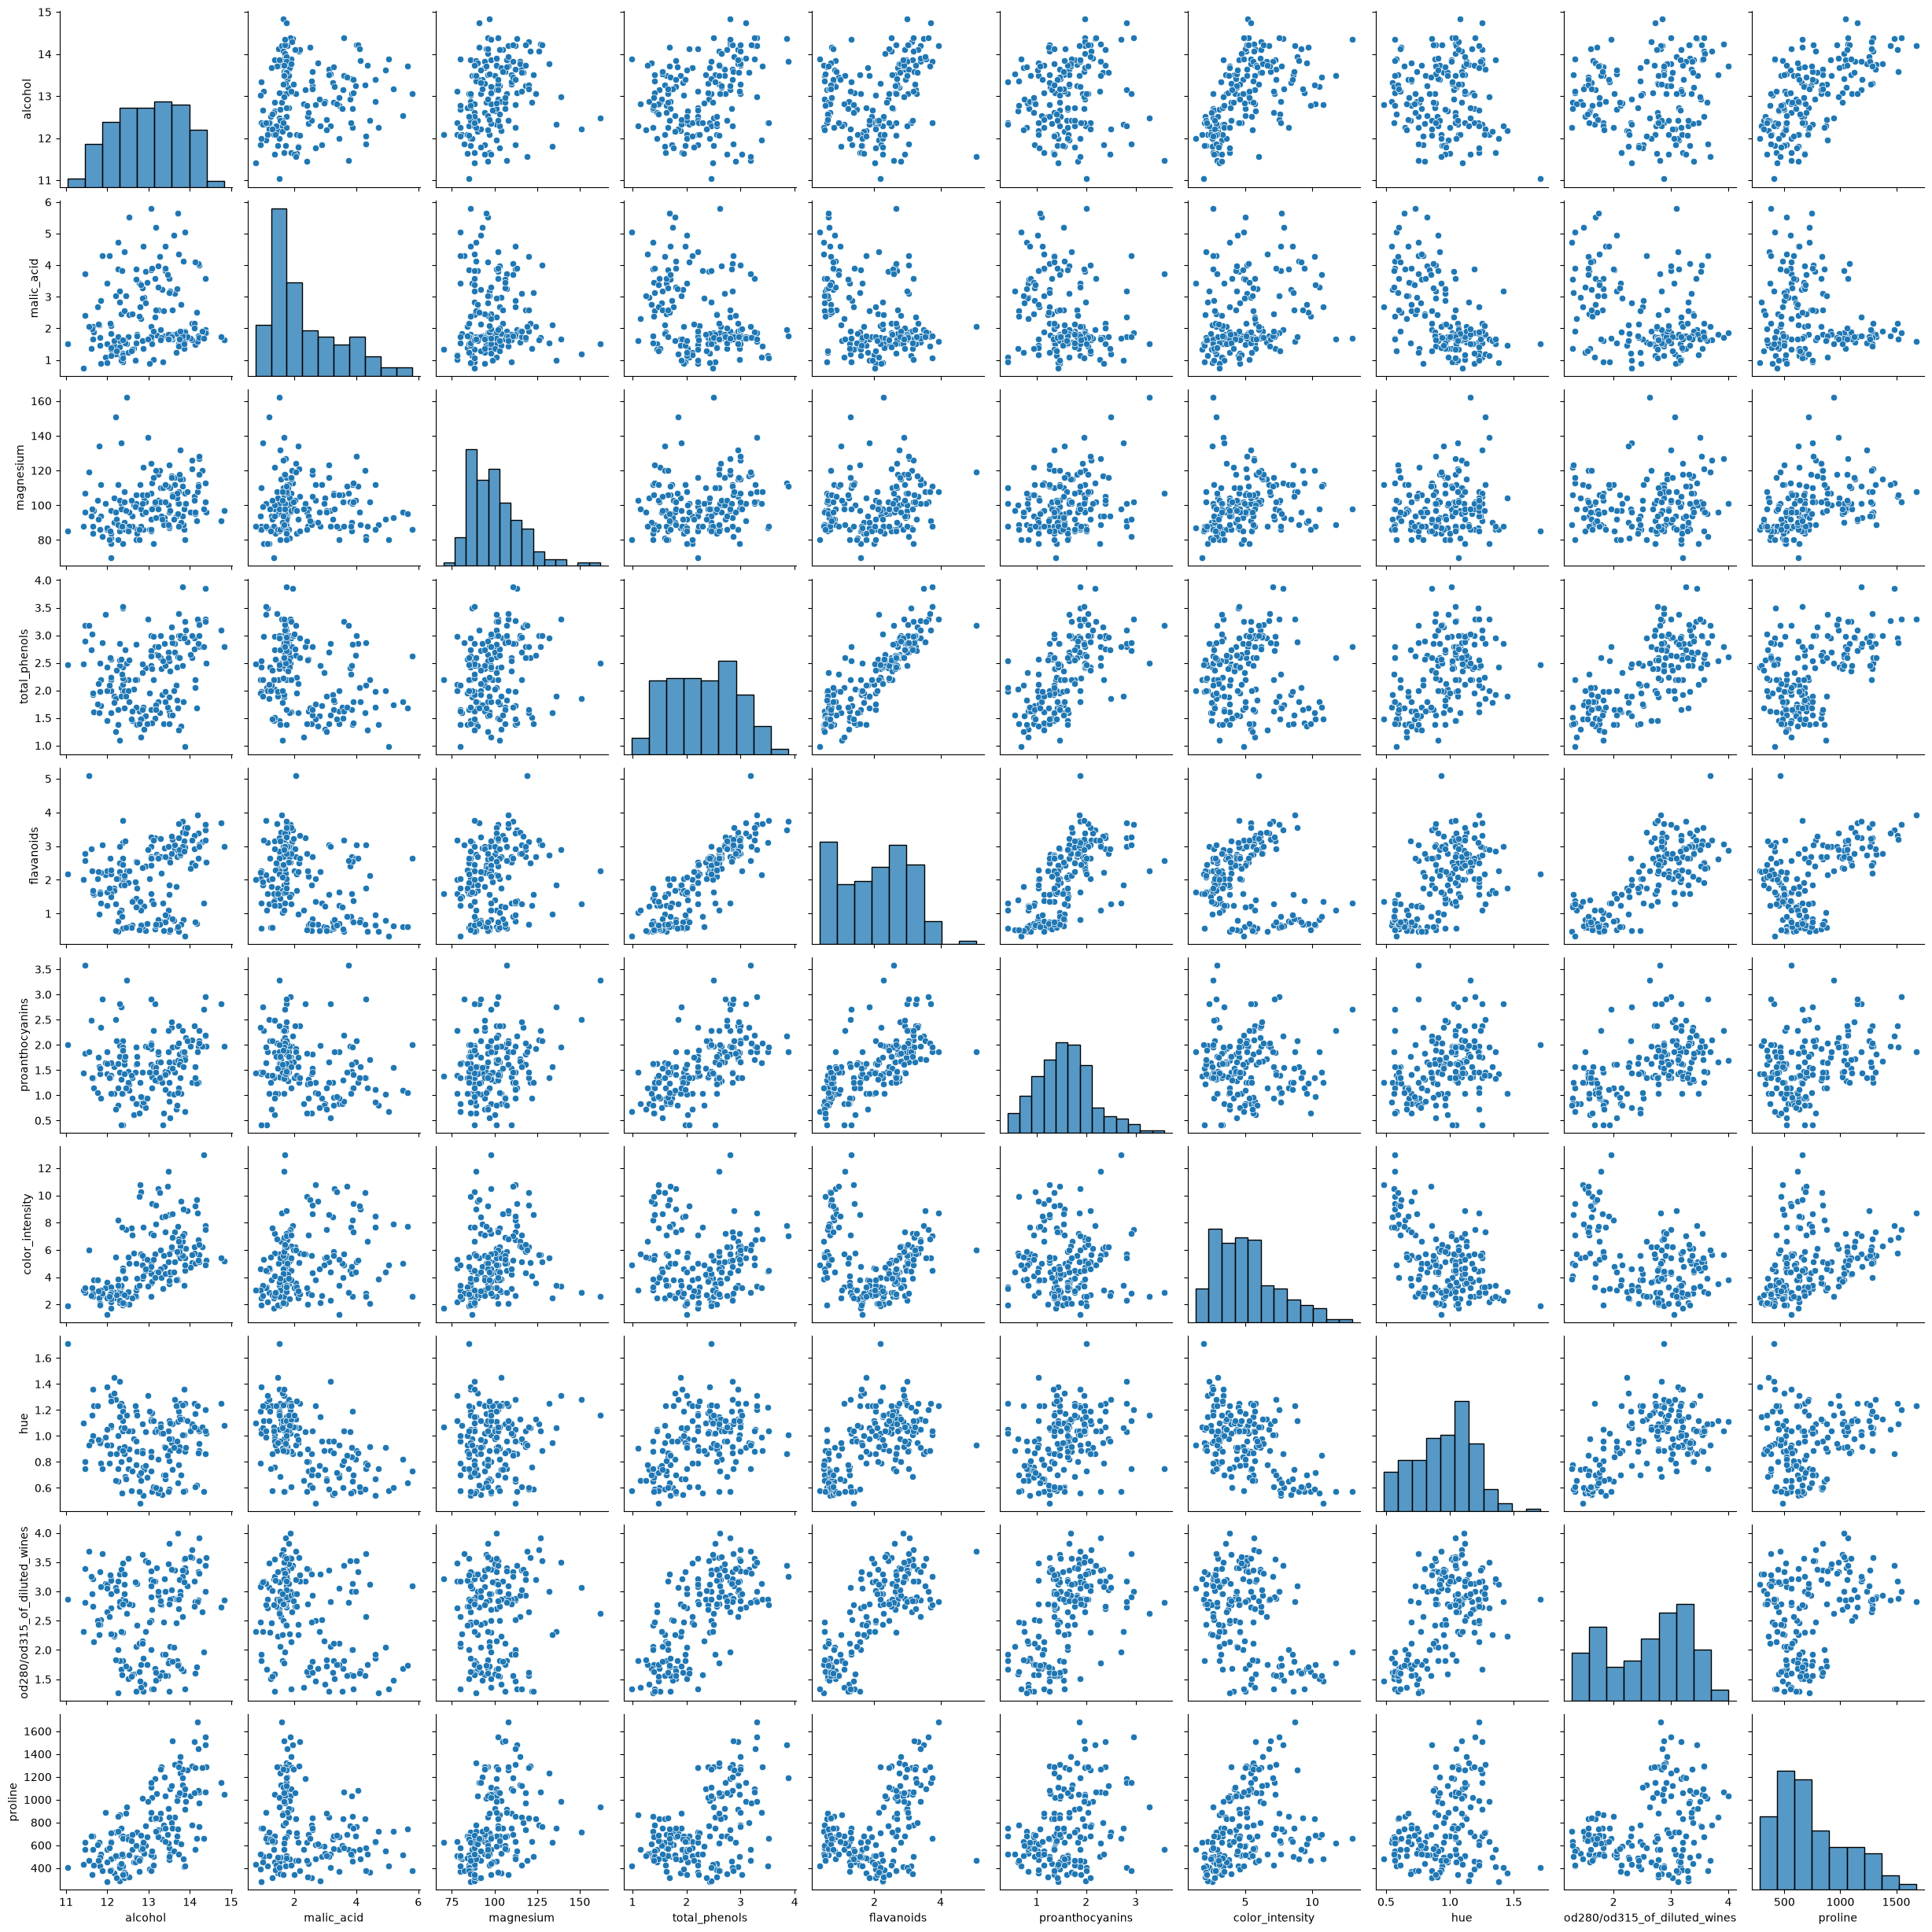

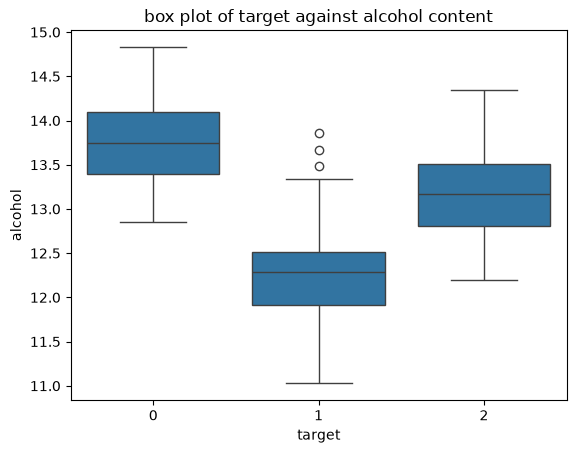

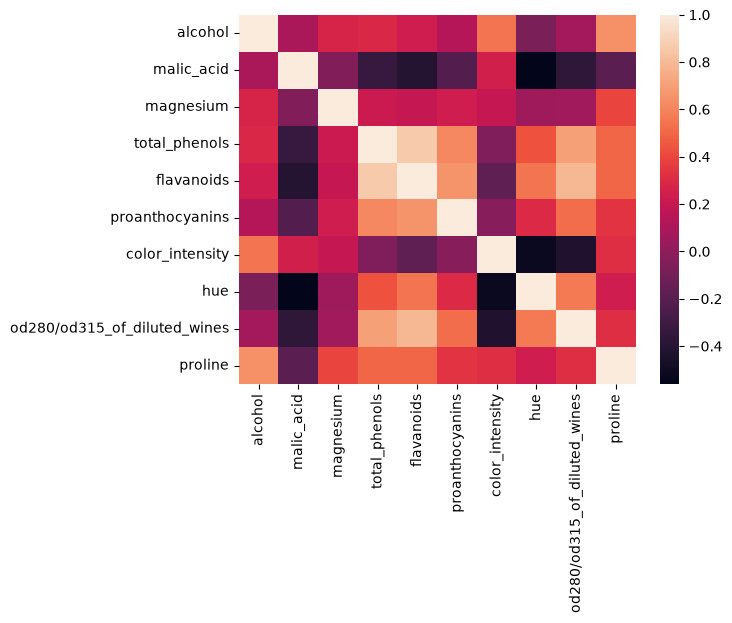

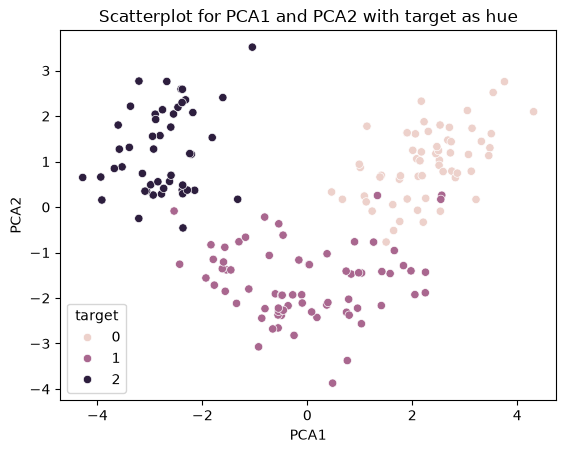

accuracy score for Logistic Regression : 0.9722222222222222
accuracy score for Decision Tree : 0.7777777777777778
accuracy score for Random Forest : 1.0
accuracy score for Logistic Regression with PCA : 0.9722222222222222
accuracy score for Decision Tree with PCA : 0.9166666666666666
accuracy score for Random Forest with PCA : 0.9722222222222222


In [4]:
main()